# Import Data

In [149]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load Data

In [150]:
raw_data = pd.read_csv("../data/jakarta_house.csv")

print("Data shape:", raw_data.shape)

print("\nPreview data:")
print(raw_data.head())

Data shape: (10000, 9)

Preview data:
   index       price       district           city  bed_rooms  bath_rooms  \
0      1  5900000000   Citra Garden  Jakarta Barat          2           4   
1      2  2700000000       Jelambar  Jakarta Barat          4           2   
2      3  2200000000       Jelambar  Jakarta Barat          3           3   
3      4  1900000000       Jelambar  Jakarta Barat          3           2   
4      5  2100000000  Tanjung Duren  Jakarta Barat          4           3   

   carport  land_area  building_area  
0        2     250.00         350.00  
1        0     100.00         225.00  
2        0      60.00         140.00  
3        0      60.00         120.00  
4        0      56.00         108.00  


In [151]:
# Hapus Kolom Index
raw_data = raw_data.drop(columns=['index'])
display(raw_data.head())

,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.00,350.00
1,2700000000,Jelambar,Jakarta Barat,4,2,0,100.00,225.00
2,2200000000,Jelambar,Jakarta Barat,3,3,0,60.00,140.00
3,1900000000,Jelambar,Jakarta Barat,3,2,0,60.00,120.00
4,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.00,108.00


# 2. Explorary Data Analyst (EDA)

In [152]:
data_explore = raw_data.copy()
data_explore.head()

,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.00,350.00
1,2700000000,Jelambar,Jakarta Barat,4,2,0,100.00,225.00
2,2200000000,Jelambar,Jakarta Barat,3,3,0,60.00,140.00
3,1900000000,Jelambar,Jakarta Barat,3,2,0,60.00,120.00
4,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.00,108.00


In [153]:
print("Data types dan cek null value")
print(data_explore.info())

print(f"\nJumlah District Unique: {data_explore["district"].nunique()}")

print("\nCity Unique")
print(data_explore['city'].unique())

Data types dan cek null value
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          10000 non-null  int64  
 1   district       10000 non-null  str    
 2   city           10000 non-null  str    
 3   bed_rooms      10000 non-null  int64  
 4   bath_rooms     10000 non-null  int64  
 5   carport        10000 non-null  int64  
 6   land_area      9997 non-null   float64
 7   building_area  9995 non-null   float64
dtypes: float64(2), int64(4), str(2)
memory usage: 625.1 KB
None

Jumlah District Unique: 253

City Unique
<StringArray>
[  'Jakarta Barat', 'Jakarta Selatan',   'Jakarta Timur',   'Jakarta Utara',
   'Jakarta Pusat']
Length: 5, dtype: str


In [154]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
data_explore.describe().T

,count,mean,std,min,25%,50%,75%,max
price,10000.00,10040290040.00,20045186721.57,1850000.00,2500000000.00,4500000000.00,9800000000.00,900000000000.00
bed_rooms,10000.00,4.25,3.18,0.00,3.00,4.00,5.00,63.00
bath_rooms,10000.00,3.52,2.90,0.00,2.00,3.00,4.00,63.00
carport,10000.00,1.58,1.74,0.00,1.00,1.00,2.00,31.00
land_area,9997.00,296.61,502.92,1.00,100.00,177.00,335.00,17714.00
building_area,9995.00,319.96,357.68,1.00,139.00,230.00,400.00,15331.00


In [155]:
# Ringkasan kualitas data
quality = pd.DataFrame({
    "dtype": data_explore.dtypes.astype(str),
    "missing": data_explore.isna().sum(),
    "missing_pct": (data_explore.isna().mean() * 100).round(2),
    "unique": data_explore.nunique(),
})
print(f"Jumlah baris: {len(data_explore):,}")
print(f"Jumlah duplikasi: {data_explore.duplicated().sum():,}")
display(quality)

Jumlah baris: 10,000
Jumlah duplikasi: 526


,dtype,missing,missing_pct,unique
price,int64,0,0.00,774
district,str,0,0.00,253
city,str,0,0.00,5
bed_rooms,int64,0,0.00,47
bath_rooms,int64,0,0.00,45
carport,int64,0,0.00,19
land_area,float64,3,0.03,1014
building_area,float64,5,0.05,678


In [156]:
print("Cek anomali nilai yang = 0:")
for col in ["price", "land_area", "building_area", "bed_rooms", "bath_rooms"]:
    zero_count = (raw_data[col] == 0).sum()
    print(f"- {col} == 0: {zero_count} baris")
display(raw_data[raw_data["bed_rooms"] == 0][["district", "city", "land_area", "building_area", "bed_rooms", "bath_rooms", "price"]].head(10))

Cek anomali nilai yang = 0:
- price == 0: 0 baris
- land_area == 0: 0 baris
- building_area == 0: 0 baris
- bed_rooms == 0: 198 baris
- bath_rooms == 0: 198 baris


,district,city,land_area,building_area,bed_rooms,bath_rooms,price
6,Kemang,Jakarta Selatan,240.00,240.00,0,0,6500000000
50,Jelambar,Jakarta Barat,88.00,218.00,0,3,1850000000
56,Green Lake City,Jakarta Barat,90.00,240.00,0,3,2680000000
58,Cibubur,Jakarta Timur,1249.00,1000.00,0,0,7000000000
383,Kebon Jeruk,Jakarta Barat,141.00,300.00,0,4,4750000000
457,Pondok Indah,Jakarta Selatan,120.00,120.00,0,0,4700000000
479,Kemang,Jakarta Selatan,900.00,900.00,0,0,16900000000
481,Kemayoran,Jakarta Pusat,549.00,880.00,0,0,11400000000
568,Pantai Indah Kapuk,Jakarta Utara,537.00,450.00,0,0,19000000000
576,Sunter,Jakarta Utara,300.00,320.00,0,0,5550000000


## 2.1 Distribusi Harga Rumah di Jakarta

In [157]:
# Copy Data untuk kepentingan membuat plot
plot_data = data_explore.copy()
plot_data["price_miliar"] = plot_data["price"] / 1e9

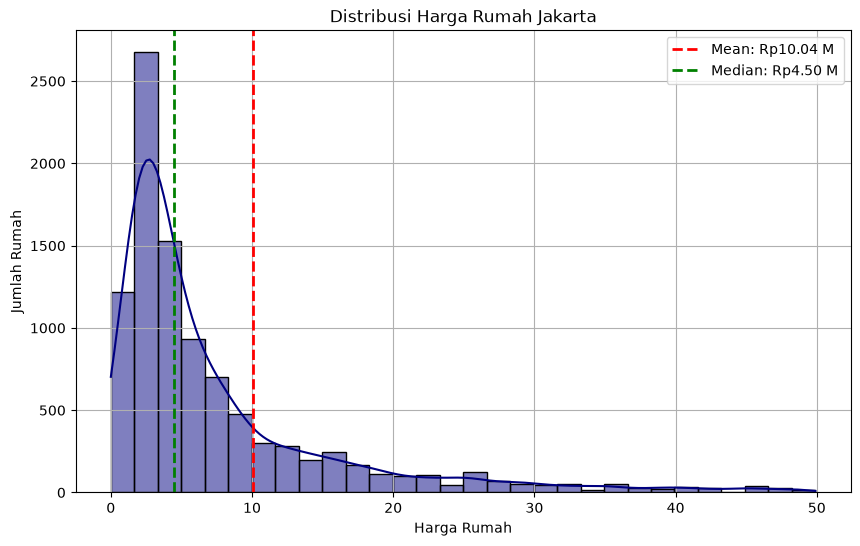

In [158]:
harga_miliar = plot_data["price_miliar"]
harga_mean = harga_miliar.mean()
harga_median = harga_miliar.median()

plt.figure(figsize=(10,6))

# Harga Rumah Jakarta < 50 M (Menghindari 1-2 data extreme)
sns.histplot(harga_miliar[harga_miliar < 50], bins=30, kde=True, color="navy")

plt.title("Distribusi Harga Rumah Jakarta")
plt.xlabel("Harga Rumah")
plt.ylabel("Jumlah Rumah")

plt.axvline(harga_mean, color="red", linestyle="--", linewidth=2, label=f"Mean: Rp{harga_mean:.2f} M")
plt.axvline(harga_median, color="green", linestyle="--", linewidth=2, label=f"Median: Rp{harga_median:.2f} M")

plt.legend()
plt.grid(True)
plt.show()

## 2.2 Analisis Harga Berdasarkan Lokasi & Luas Tanah

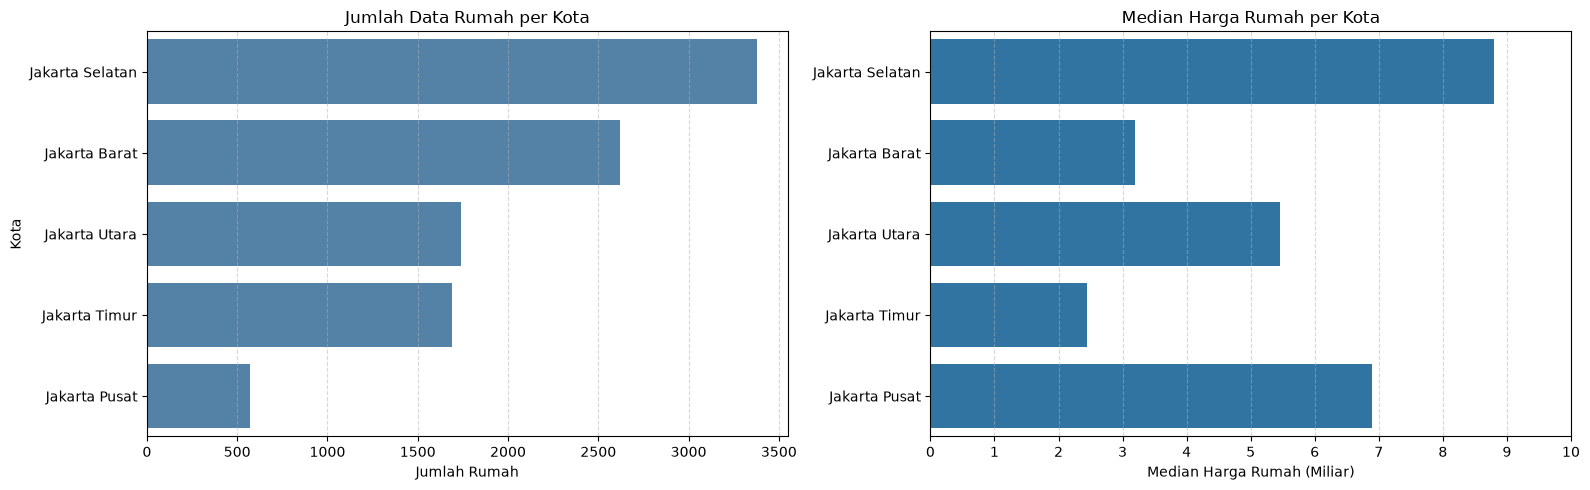

,count,mean,median,min,max
city,,,,,
Jakarta Pusat,570,19758250877.19,6900000000.00,116000000,179000000000
Jakarta Selatan,3379,16704478070.44,8800000000.00,12500000,900000000000
Jakarta Utara,1739,8592812593.44,5450000000.00,2300000,85000000000
Jakarta Barat,2622,4523864263.92,3200000000.00,7100000,77500000000
Jakarta Timur,1690,3486267928.99,2450000000.00,1850000,81000000000


In [159]:
category_counts = plot_data["city"].value_counts().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x=category_counts.values, y=category_counts.index, ax=axes[0], color="steelblue")
axes[0].grid(axis="x", linestyle="--", alpha=0.5)
axes[0].set_title("Jumlah Data Rumah per Kota")
axes[0].set_xlabel("Jumlah Rumah")
axes[0].set_ylabel("Kota")

sns.barplot(
    data=plot_data,
    x="price_miliar",
    y="city",
    order=category_counts.index,
    estimator="median",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_xticks(np.arange(0, 11, 1))
axes[1].grid(axis="x", linestyle="--", alpha=0.5)
axes[1].set_title("Median Harga Rumah per Kota")
axes[1].set_xlabel("Median Harga Rumah (Miliar)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

display(
    plot_data.groupby("city")["price"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

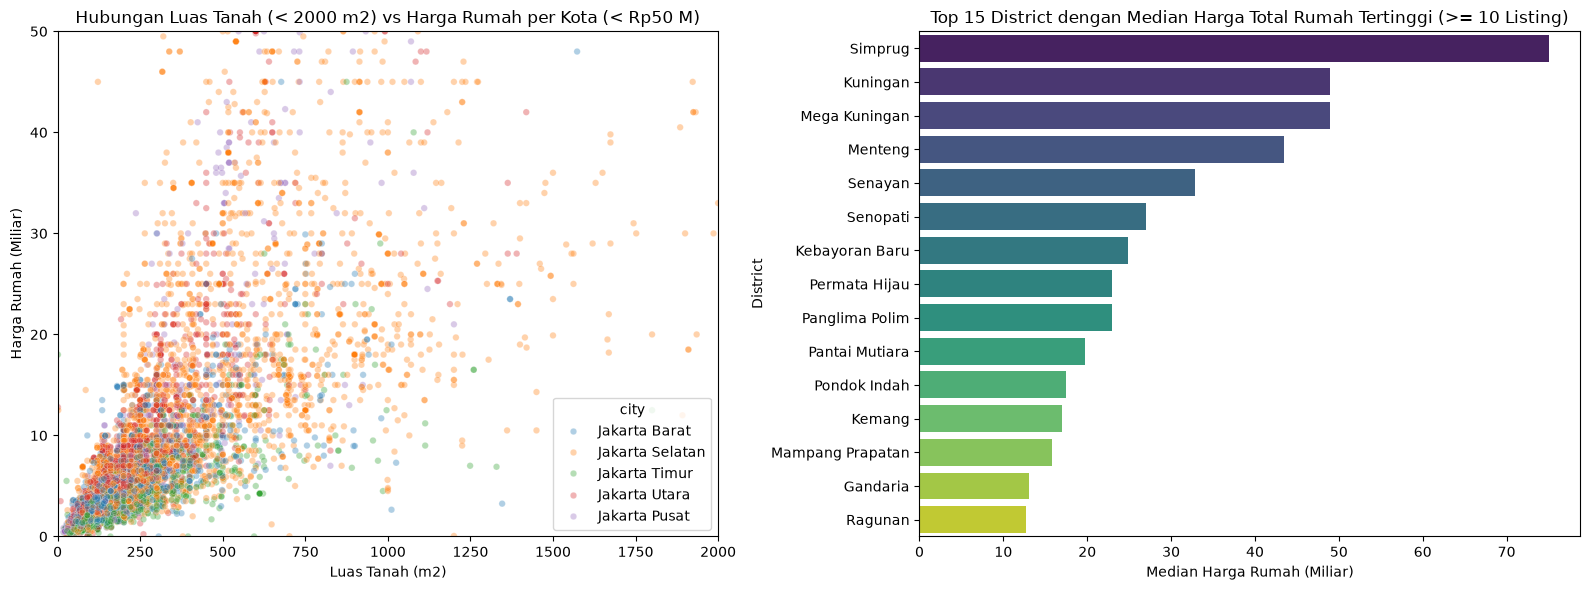

In [160]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatterplot Luas Tanah < 2000 m2 dan Harga Rumah per Kota < Rp50 M
sns.scatterplot(data=plot_data, x="land_area", y="price_miliar", hue="city", alpha=0.35, s=22, ax=axes[0])
axes[0].set_xlim(0, 2000)
axes[0].set_ylim(0, 50)
axes[0].set_title("Hubungan Luas Tanah (< 2000 m2) vs Harga Rumah per Kota (< Rp50 M)")
axes[0].set_xlabel("Luas Tanah (m2)")
axes[0].set_ylabel("Harga Rumah (Miliar)")

# Memfilter distrik minimal 10 listing agar median tidak bias oleh 1-2 data extreme
district_counts = plot_data["district"].value_counts()
valid_districts = district_counts[district_counts >= 10].index

# Barplot
top_districts = (
    plot_data[plot_data["district"].isin(valid_districts)].groupby("district")["price_miliar"].median().sort_values(ascending=False).head(15)
)

sns.barplot(x=top_districts.values, y=top_districts.index, hue=top_districts.index, palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Top 15 District dengan Median Harga Total Rumah Tertinggi (>= 10 Listing)")
axes[1].set_xlabel("Median Harga Rumah (Miliar)")
axes[1].set_ylabel("District")

plt.tight_layout()
plt.show()

## 2.3 Rumah Termurah dan Termahal

In [161]:
data_columns = ["district", "city", "bed_rooms", "bath_rooms", "land_area", "building_area", "price"]

print("10 RUMAH TERMURAH")
display(data_explore.nsmallest(10, "price")[data_columns])

print("10 RUMAH TERMAHAL")
display(data_explore.nlargest(10, "price")[data_columns])

10 RUMAH TERMURAH


,district,city,bed_rooms,bath_rooms,land_area,building_area,price
3744,Metland Menteng,Jakarta Timur,2,2,96.00,100.00,1850000
3295,Kota Wisata,Jakarta Timur,5,4,160.00,200.00,2200000
3291,Sunter,Jakarta Utara,3,2,50.00,80.00,2300000
3289,Golf Island,Jakarta Utara,3,3,90.00,100.00,3800000
3290,Cibubur,Jakarta Timur,4,2,395.00,63.00,4900000
3298,Pondok Kelapa,Jakarta Timur,5,3,595.00,238.00,6850000
3294,Tomang,Jakarta Barat,4,2,306.00,315.00,7100000
3293,Kemang,Jakarta Selatan,4,4,379.00,124.00,12500000
1013,Pantai Indah Kapuk 2,Jakarta Utara,4,5,45.00,110.00,15000000
1012,Pantai Indah Kapuk 2,Jakarta Utara,4,4,90.00,127.00,22000000


10 RUMAH TERMAHAL


,district,city,bed_rooms,bath_rooms,land_area,building_area,price
837,Pondok Indah,Jakarta Selatan,15,10,10847.00,4850.00,900000000000
577,Kebagusan,Jakarta Selatan,4,3,17714.00,6800.00,370000000000
5416,TB Simatupang,Jakarta Selatan,30,45,16791.00,10000.00,370000000000
4435,Lenteng Agung,Jakarta Selatan,30,20,16057.00,3000.00,337000000000
6289,Pondok Indah,Jakarta Selatan,6,5,4260.00,2500.00,265000000000
6671,Pondok Indah,Jakarta Selatan,6,6,4189.00,1841.00,250000000000
3592,Jagakarsa,Jakarta Selatan,4,4,97.00,180.00,245000000000
735,Pondok Indah,Jakarta Selatan,13,9,4190.00,1840.00,235000000000
2552,Kebayoran Baru,Jakarta Selatan,5,5,1358.00,730.00,190000000000
4449,Pondok Indah,Jakarta Selatan,6,6,1620.00,1250.00,190000000000


## 2.4 Korelasi Antar Fitur & Deteksi Outlier

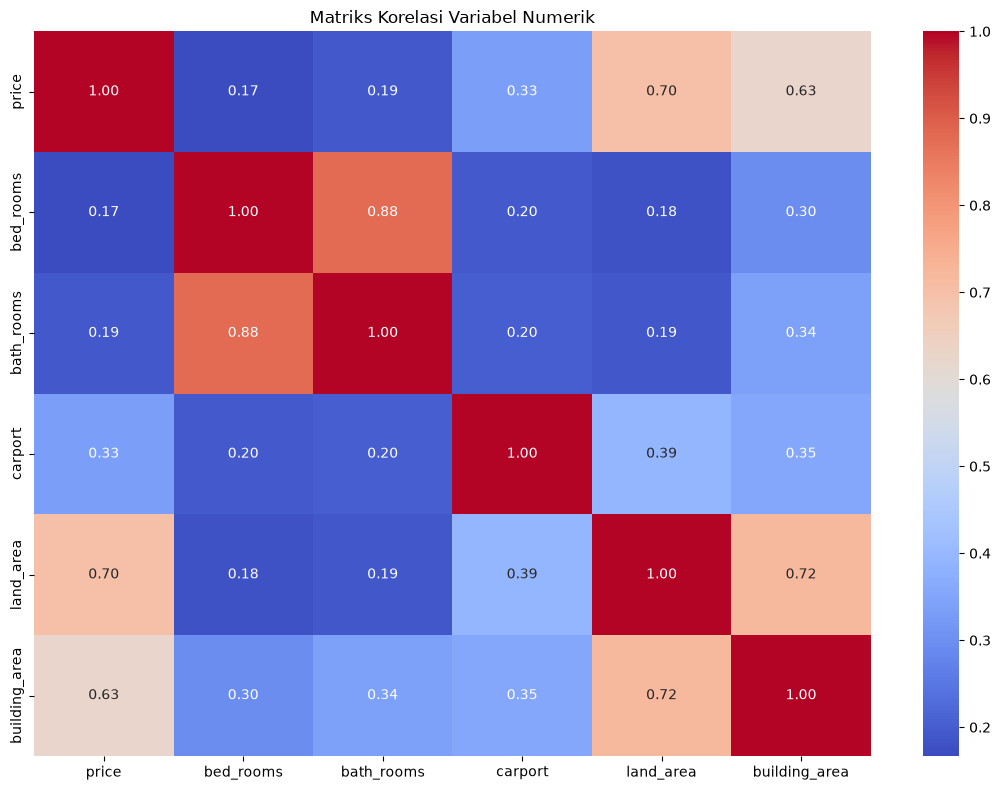

,Korelasi dengan Target
land_area,0.70
building_area,0.63
carport,0.33
bath_rooms,0.19
bed_rooms,0.17


In [162]:
# Korelasi fitur numerik terhadap target
numeric_columns = data_explore.select_dtypes(include="number").columns
correlation = data_explore[numeric_columns].corr(numeric_only=True)
plt.figure(figsize=(11, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriks Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()

display(correlation["price"].drop("price").sort_values(key=abs, ascending=False).to_frame("Korelasi dengan Target"))

In [163]:
# Pemeriksaan outlier berbasis IQR
outlier_summary = []
for column in numeric_columns:
    q1, q3 = data_explore[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((data_explore[column] < lower) | (data_explore[column] > upper)).sum()
    outlier_summary.append({"column": column, "IQR": round(iqr, 2), "Batas Bawah": round(lower, 2), "Batas Atas": round(upper, 2),"Jumlah Outlier": count, "Persentase Outlier": round(count / len(data_explore) * 100, 2)})

display(pd.DataFrame(outlier_summary).sort_values("Jumlah Outlier", ascending=False))

print("Insight awal:")
print(f"- Korelasi terkuat dengan harga: {correlation['price'].drop('price').abs().idxmax()}.")
print(f"- Kota dengan median harga tertinggi: {data_explore.groupby('city')['price'].median().idxmax()}.")
print(f"- Kolom dengan missing value: {quality[quality['missing'] > 0].index.tolist()}.")

,column,IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase Outlier
0,price,7300000000.00,-8450000000.00,20750000000.00,1107,11.07
4,land_area,235.00,-252.50,687.50,881,8.81
3,carport,1.00,-0.50,3.50,795,7.95
5,building_area,261.00,-252.50,791.50,656,6.56
1,bed_rooms,2.00,0.00,8.00,308,3.08
2,bath_rooms,2.00,-1.00,7.00,270,2.70


Insight awal:
- Korelasi terkuat dengan harga: land_area.
- Kota dengan median harga tertinggi: Jakarta Selatan.
- Kolom dengan missing value: ['land_area', 'building_area'].


# Data Cleaning

In [164]:
clean_data = raw_data.copy()
display(clean_data.head())

data_awal = len(clean_data)
print(f"Jumlah data awal: {data_awal:,} baris")

,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.00,350.00
1,2700000000,Jelambar,Jakarta Barat,4,2,0,100.00,225.00
2,2200000000,Jelambar,Jakarta Barat,3,3,0,60.00,140.00
3,1900000000,Jelambar,Jakarta Barat,3,2,0,60.00,120.00
4,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.00,108.00


Jumlah data awal: 10,000 baris


In [165]:
# Cek missing value
print("\nMissing values")
missing = clean_data.isnull().sum()
print(missing[missing > 0])

clean_data = clean_data.dropna(subset=["land_area", "building_area"])
print(f"Setelah Hapus Missing Value: {len(clean_data):,} baris")



Missing values
land_area        3
building_area    5
dtype: int64
Setelah Hapus Missing Value: 9,992 baris


In [166]:
# Hapus Duplicate Values
print(f"Jumlah baris: {len(clean_data):,}")
print(f"Jumlah duplikasi: {clean_data.duplicated().sum():,}")

clean_data = clean_data.drop_duplicates()

print(f"Setelah Hapus Duplikat: {len(clean_data):,} baris")


Jumlah baris: 9,992
Jumlah duplikasi: 526
Setelah Hapus Duplikat: 9,466 baris


In [167]:
# Hapus Anomali properti (Tanpa Bedrooms dan Bathrooms)
clean_data = clean_data[(clean_data["bed_rooms"] > 0) & (clean_data["bath_rooms"] > 0)]
print(f"Setelah Hapus Anomali (Filtering): {len(clean_data):,} baris")

Setelah Hapus Anomali (Filtering): 9,229 baris


In [168]:
# Cek Batas Harga Rumah Wajar
cek = clean_data[
    (clean_data["price"] >= 300000000) & ((clean_data["price"] / clean_data["land_area"]) >= 3500000)].sort_values(by="price")
cek.head(20)

,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
534,300000000,Rawamangun,Jakarta Timur,2,1,0,37.00,25.00
2443,307000000,Cilincing,Jakarta Utara,2,1,0,69.00,69.00
5762,315000000,Jagakarsa,Jakarta Selatan,3,2,1,26.00,52.00
3322,330000000,Ciracas,Jakarta Timur,2,1,1,40.00,40.00
2559,350000000,Jembatan Lima,Jakarta Barat,2,1,0,40.00,72.00
4201,350000000,Condet,Jakarta Timur,2,2,0,26.00,52.00
9056,350000000,Lubang Buaya,Jakarta Timur,2,1,1,34.00,34.00
9054,365000000,Ciracas,Jakarta Timur,2,1,1,40.00,40.00
7496,375000000,Klender,Jakarta Timur,2,2,0,50.00,60.00
543,380000000,Cakung,Jakarta Timur,2,1,0,56.00,40.00


In [169]:
clean_data = clean_data[
    (clean_data["price"] >= 300000000) & ((clean_data["price"] / clean_data["land_area"]) >= 3500000)].sort_values(by="price")
print(f"Setelah Filter Harga & Harga/m2: {len(clean_data):,} baris")

Setelah Filter Harga & Harga/m2: 9,205 baris


In [170]:
clean_data = clean_data.reset_index(drop=True)
print(f"Total Data Bersih: {len(clean_data):,} baris")

display(clean_data.head())

Total Data Bersih: 9,205 baris


,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,300000000,Rawamangun,Jakarta Timur,2,1,0,37.00,25.00
1,307000000,Cilincing,Jakarta Utara,2,1,0,69.00,69.00
2,315000000,Jagakarsa,Jakarta Selatan,3,2,1,26.00,52.00
3,330000000,Ciracas,Jakarta Timur,2,1,1,40.00,40.00
4,350000000,Jembatan Lima,Jakarta Barat,2,1,0,40.00,72.00


# Data Preprocessing

In [171]:
encoded_data = clean_data.copy()

encoded_data.head()

,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,300000000,Rawamangun,Jakarta Timur,2,1,0,37.00,25.00
1,307000000,Cilincing,Jakarta Utara,2,1,0,69.00,69.00
2,315000000,Jagakarsa,Jakarta Selatan,3,2,1,26.00,52.00
3,330000000,Ciracas,Jakarta Timur,2,1,1,40.00,40.00
4,350000000,Jembatan Lima,Jakarta Barat,2,1,0,40.00,72.00


In [172]:
encoded_data["total_bedrooms"] = encoded_data["total_bedrooms"].fillna(
    encoded_data.groupby("ocean_proximity")["total_bedrooms"].transform("median")
)

null_check = encoded_data["total_bedrooms"].isnull().sum()
print("Missing Value:", null_check)

KeyError: 'total_bedrooms'

In [ ]:
ocean_dummy = pd.get_dummies(encoded_data["ocean_proximity"], dtype=int)
encoded_data = encoded_data.drop(columns=["ocean_proximity"])
encoded_data = pd.concat([encoded_data, ocean_dummy], axis=1)

In [ ]:
encoded_data.columns = [
    col.lower().replace('<', '_').replace(' ', '_') for col in encoded_data.columns
]

display(encoded_data)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,_1h_ocean,inland,island,near_bay,near_ocean
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,0,1,0,0,0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,0,1,0,0,0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,0,1,0,0,0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,0,1,0,0,0


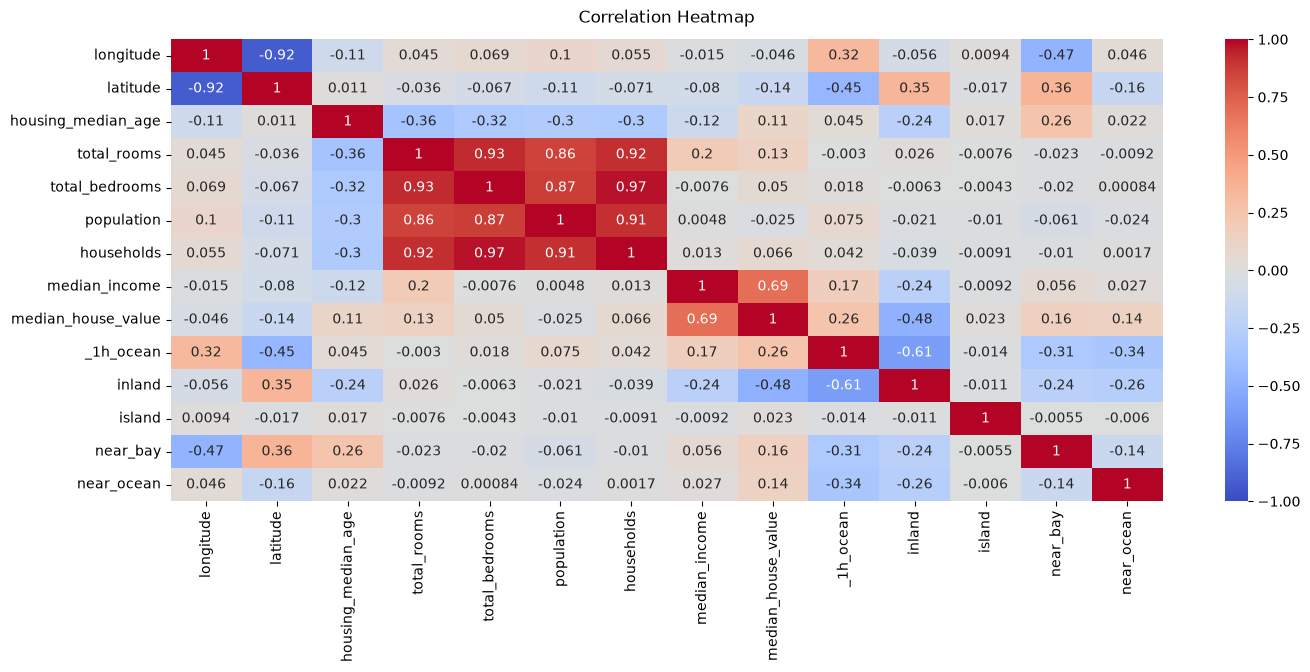

In [ ]:
plt.figure(figsize=(16, 6))

heatmap = sns.heatmap(
    encoded_data.corr(),
    vmin=-1, vmax=1, annot=True,
    cmap="coolwarm"
)

heatmap.set_title("Correlation Heatmap", fontdict={"fontsize":12}, pad=12)

plt.show()

In [ ]:
final_data = encoded_data.copy()
final_data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,_1h_ocean,inland,island,near_bay,near_ocean
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0


# Feature Engineering

In [ ]:

fe_data = final_data.copy()
display(fe_data)

fe_data["rooms_per_household"] = fe_data["total_rooms"] / fe_data["households"]
fe_data["bedrooms_per_room"] = fe_data["total_bedrooms"] / fe_data["total_rooms"]
fe_data["population_per_household"] = fe_data["population"] / fe_data["households"]

skewed_cols = ["total_rooms", "total_bedrooms", "population", "households"]
for col in skewed_cols:
    fe_data[f"log_{col}"] = np.log1p(fe_data[col])

fe_data = fe_data.replace([np.inf, -np.inf], np.nan).dropna()
print("Shape setelah feature engineering:", fe_data.shape)

y = fe_data["median_house_value"]
X = fe_data.drop(columns=["median_house_value"] + skewed_cols)

print("Fitur yang dipakai:")
print(X.columns.tolist())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,_1h_ocean,inland,island,near_bay,near_ocean
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,0,1,0,0,0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,0,1,0,0,0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,0,1,0,0,0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,0,1,0,0,0


Shape setelah feature engineering: (20640, 21)
Fitur yang dipakai:
['longitude', 'latitude', 'housing_median_age', 'median_income', '_1h_ocean', 'inland', 'island', 'near_bay', 'near_ocean', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'log_total_rooms', 'log_total_bedrooms', 'log_population', 'log_households']
Train: (16512, 16) | Test: (4128, 16)


# Experimentation

In [ ]:
models = {
    "LR": LinearRegression(),
    "RFR": RandomForestRegressor(n_jobs=-1),
    "XGBR": xgb.XGBRegressor()
}

In [ ]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"{name} | R2: {r2:.4f} | MAE: ${mae:,.0f} | RMSE: ${rmse:,.0f}")

LR | R2: 0.6041 | MAE: $49,821 | RMSE: $72,026
RFR | R2: 0.8077 | MAE: $32,299 | RMSE: $50,198
XGBR | R2: 0.8327 | MAE: $30,623 | RMSE: $46,817


# Final Model

In [ ]:

rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : ${mae:,.0f}")
print(f"RMSE : ${rmse:,.0f}")
print(f"R²   : {r2:.4f}")

MAE  : $32,358
RMSE : $50,370
R²   : 0.8064
